# Bioreactor Foam Detection — Phase 1: Synthetic Dataset Generation

This notebook builds a **100-image synthetic dataset** of one 500 mL laboratory bioreactor under different
operating conditions, using the OpenAI image **edit** endpoint with your reference photo as the visual basis
for every image.

| Foam class | Train | Validation | Test | Total |
|---|---:|---:|---:|---:|
| `no_foam` | 15 | 5 | 5 | 25 |
| `minimal_foam` | 15 | 5 | 5 | 25 |
| `moderate_foam` | 15 | 5 | 5 | 25 |
| `heavy_foam` | 15 | 5 | 5 | 25 |
| **Total** | **60** | **20** | **20** | **100** |

**Setup instructions**

1. **Configure** model, paths, prompts, retry and cost settings (Section 2).
2. **Plan**: build a deterministic *scenario manifest* — every image's class, operating condition, split and
   exact prompt — **before** any API call (Section 5). Splits are assigned per *scenario*, not per image.
3. **Generate** images one at a time, saving each immediately; reruns resume where they stopped (Sections 6–8).
4. **Validate** counts, splits, leakage, file integrity and near-duplicates (Section 9).
5. **Visualize** the dataset (Section 10).

**Run modes** (set `RUN_MODE` in Section 2)

| Mode | What happens | API cost |
|---|---|---|
| `"dry_run"` *(default)* | Builds and validates the manifest. No API key requested, no API calls. | none |
| `"test"` | Generates `TEST_IMAGE_COUNT` images (one per class first) into the real dataset folders. | a few images |
| `"full"` | Generates every image that is still missing. | up to the full dataset |

Images from a `test` run count toward the dataset — a later `full` run only generates what is still missing.

> ⚠️ Images are only generated when you run this notebook with `RUN_MODE = "test"` or `"full"`.
> Use **Kernel → Restart & Run All** after changing settings.

## 1. Imports and environment check

In [1]:
import base64
import hashlib
import io
import itertools
import logging
import math
import os
import random
import re
import shutil
import sys
import time
from datetime import datetime, timezone
from getpass import getpass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import openai
import pandas as pd
from IPython.display import display
from openai import OpenAI
from PIL import Image, ImageOps

if sys.version_info < (3, 11):
    raise RuntimeError(f"Python 3.11+ is required, found {sys.version.split()[0]}")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
print(f"Python {sys.version.split()[0]} | openai {openai.__version__} | pandas {pd.__version__} | Pillow {Image.__version__}")

Python 3.14.3 | openai 3.37.0 | pandas 3.1.0 | Pillow 13.0.0


## 2. Configuration

All settings live here. The most important ones:

- **`RUN_MODE`** — `"dry_run"`, `"test"` or `"full"` (see the table above).
- **`REFERENCE_IMAGE_PATH`** — Relative paths are resolved from the `notebooks/` folder.
- **`MODEL`** — an OpenAI GPT Image model that accepts input images through `client.images.edit`.
  `gpt-image-2` is the default. `gpt-image-1.5` / `gpt-image-1` also work and additionally accept
  `input_fidelity="high"` for stronger preservation of the reference (sent automatically for those models).
  DALL·E 3 is **not** suitable: it cannot take a reference image.
- **`IMAGE_SIZE`** — `"match_reference"` picks an output size with the reference photo's aspect ratio
  (arbitrary sizes on `gpt-image-2*`, nearest standard size on older models). You can also set an explicit
  size such as `"1024x1536"`.
- **`ESTIMATED_COST_PER_IMAGE_USD`** — *your* estimate of the price per image. Check the current
  [OpenAI pricing page](https://openai.com/api/pricing/) for your model/size/quality and update it.
  All costs shown by this notebook are **estimates**; your actual bill is on the
  [OpenAI usage dashboard](https://platform.openai.com/usage).

The API key is **never** stored in this notebook. Set `OPENAI_API_KEY` in your environment, or you will be
prompted for it with a hidden input field (only in `test` / `full` mode).

In [2]:
# ── Run mode ─────────────────────────────────────────────────────────────────
RUN_MODE = "dry_run"       # "dry_run" | "test" | "full"
TEST_IMAGE_COUNT = 4          # images generated in "test" mode (spread across foam classes)

# ── Paths ────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
REFERENCE_IMAGE_PATH = "../reference/prototype.webp"  # PNG, JPEG or WebP; relative to notebooks/
DATA_DIR = PROJECT_ROOT / "data"
METADATA_DIR = PROJECT_ROOT / "metadata"
ARCHIVE_DIR = PROJECT_ROOT / "archive"
PLAN_PATH = METADATA_DIR / "generation_plan.csv"
METADATA_PATH = METADATA_DIR / "metadata.csv"
VALIDATION_REPORT_PATH = METADATA_DIR / "validation_report.csv"

# ── Model and image settings ─────────────────────────────────────────────────
MODEL = "gpt-image-2"
IMAGE_SIZE = "match_reference"   # "match_reference" | "1024x1536" | "1536x1024" | "1024x1024" | "auto" | "WxH" (gpt-image-2*)
IMAGE_QUALITY = "low"           # "low" | "medium" | "high" | "auto"
INPUT_FIDELITY = "high"          # only sent to models listed in INPUT_FIDELITY_MODELS
INPUT_FIDELITY_MODELS = {"gpt-image-1", "gpt-image-1.5"}
ARBITRARY_SIZE_MODEL_PREFIXES = ("gpt-image-2",)   # models that accept any WIDTHxHEIGHT (multiples of 16)
REFERENCE_MAX_EDGE = 2048        # larger reference photos are downscaled before upload

# ── Dataset design ───────────────────────────────────────────────────────────
FOAM_CLASSES = ["no_foam", "minimal_foam", "moderate_foam", "heavy_foam"]
SPLITS = ["train", "validation", "test"]
TOTAL_IMAGES = 100
IMAGES_PER_CLASS_PER_SPLIT = {"train": 15, "validation": 5, "test": 5}
# How each split's per-class quota is built from scenarios (see Section 5 for the reasoning).
SPLIT_DESIGN = {
    "train":      {"scenarios_per_class": 5, "images_per_scenario": 3},
    "validation": {"scenarios_per_class": 5, "images_per_scenario": 1},
    "test":       {"scenarios_per_class": 5, "images_per_scenario": 1},
}
RANDOM_SEED = 42

# ── Retries and pacing ───────────────────────────────────────────────────────
MAX_ATTEMPTS_PER_IMAGE = 5
INITIAL_BACKOFF_SECONDS = 5.0
MAX_BACKOFF_SECONDS = 120.0
REQUEST_TIMEOUT_SECONDS = 300.0
PAUSE_BETWEEN_REQUESTS_SECONDS = 1.0
MAX_CONSECUTIVE_FAILURES = 3     # stop the run if this many images in a row fail

# ── Cost monitoring (ESTIMATES ONLY) ─────────────────────────────────────────
ESTIMATED_COST_PER_IMAGE_USD = 0.25   # update from the OpenAI pricing page for your model/size/quality
ESTIMATED_BUDGET_LIMIT_USD = 40.0     # stop a run before its estimated cost exceeds this; None disables

# ── Similarity check ─────────────────────────────────────────────────────────
RUN_SIMILARITY_CHECK = True
HASH_SIZE = 16                   # dHash grid → HASH_SIZE² bits
SIMILARITY_THRESHOLD = 0.08      # flag cross-split pairs whose fraction of differing hash bits is ≤ this

# ── Starting over ────────────────────────────────────────────────────────────
# True moves existing data/ and metadata/ into archive/run_<timestamp>/ (nothing is deleted).
# Set it back to False immediately afterwards.
ARCHIVE_EXISTING_RUN = False

# ── Sanity checks on the configuration ───────────────────────────────────────
assert RUN_MODE in {"dry_run", "test", "full"}, f"Unknown RUN_MODE: {RUN_MODE!r}"
for _split, _design in SPLIT_DESIGN.items():
    assert _design["scenarios_per_class"] * _design["images_per_scenario"] == IMAGES_PER_CLASS_PER_SPLIT[_split], (
        f"SPLIT_DESIGN[{_split!r}] does not produce {IMAGES_PER_CLASS_PER_SPLIT[_split]} images per class"
    )
assert sum(IMAGES_PER_CLASS_PER_SPLIT.values()) * len(FOAM_CLASSES) == TOTAL_IMAGES, "Split quotas do not add up to TOTAL_IMAGES"
print(f"RUN_MODE = {RUN_MODE!r} | MODEL = {MODEL!r} | project root = {PROJECT_ROOT}")

RUN_MODE = 'full' | MODEL = 'gpt-image-2' | project root = /Users/nonna/Desktop/nola-bio/bioreactor-foam-detection


### 2.1 Prompts

Every image prompt is assembled from these blocks, in this order:

1. **`BASE_IMAGE_PROMPT`** - your exact prompt, used verbatim. **Paste it below.**
2. **`REFERENCE_PRESERVATION_PROMPT`** - keep the vessel, hardware, camera and background from the reference.
3. **`FOAM_CLASS_PROMPTS[class]`** — the foam category, with clear, non-overlapping coverage ranges so the
   four classes are visually distinguishable (≈0 %, <10 %, ≈30–70 %, ~100 % + rising into headspace).
4. **Operating condition** — the scenario's liquid level, medium color, turbidity, agitation, foam pattern,
   bubble size and lighting (generated in Section 5).
5. **Capture variation** — small shot-to-shot differences for scenarios with several images.
6. **`NEGATIVE_PROMPT`** — things to avoid.

The final prompt for every image is stored in `generation_plan.csv` and `metadata.csv`.

In [3]:
BASE_IMAGE_PROMPT = """
A photorealistic, high-resolution photograph of a 500 mL benchtop laboratory bioreactor in a modern
bioprocess laboratory, photographed from outside the vessel at bench height. The bioreactor has a clear
borosilicate glass cylindrical vessel held in a polished stainless-steel frame with vertical support rods,
a stainless-steel base ring on black rubber feet, and a stainless-steel headplate carrying several ports,
sensor probes with black and red connectors, a central stirrer shaft with two flat-blade impellers, dip
tubes and translucent silicone tubing. The vessel stands on a brushed stainless-steel lab bench, with
softly out-of-focus laboratory equipment and reagent bottles in the background.

Style: realistic laboratory documentation photography, natural colors, accurate glass refraction and
reflections, sharp focus on the vessel and its contents, gentle background blur, no stylization or
post-processing effects.

Important: the liquid, foam and bubbles visible in the reference photo are NOT part of the scene to copy.
Render the liquid volume, color, turbidity, surface motion, foam and bubbles exactly as specified in the
FOAM LEVEL and OPERATING CONDITION sections below, even when they differ strongly from the reference photo.
"""
BASE_PROMPT_PLACEHOLDER = "PASTE MY IMAGE GENERATION PROMPT HERE"

REFERENCE_PRESERVATION_PROMPT = """
Use the supplied reference photograph as the exact visual basis for this image. Show the SAME physical
500 mL laboratory bioreactor as in the reference: keep the vessel's geometry, dimensions, proportions and
materials, the headplate, ports, probes, tubing, stirrer/impeller shaft, clamps and every other visible
hardware component in the same positions. Keep the same external camera position, viewing angle, focal
length, framing and scale, with the entire bioreactor visible in the frame. Keep the laboratory background,
bench and surroundings as in the reference, without adding or removing objects. Only change what happens
inside the vessel: the liquid volume, the culture medium's color and turbidity, the surface motion, and the
foam and bubbles described below. The result must look like a real, unedited photograph taken with the
same camera in the same laboratory.
"""

FOAM_CLASS_PROMPTS = {
    "no_foam": """
Foam class: NO FOAM. The liquid surface is completely free of foam: no foam layer, no bubble clusters and no
froth on the surface or at the glass wall. The meniscus is clean. Any surface motion appears only as smooth
ripples or a smooth vortex, never as bubbles or froth.
""",
    "minimal_foam": """
Foam class: MINIMAL FOAM. Only a small amount of foam: a few isolated small bubbles or thin traces of foam
covering clearly less than about 10% of the liquid surface, with no continuous foam layer. The open liquid
surface remains visible almost everywhere.
""",
    "moderate_foam": """
Foam class: MODERATE FOAM. Noticeable foam partially covers the liquid surface, roughly 30-70% coverage, as
a layer about 0.5-2 cm thick. Some open liquid surface is still clearly visible between or beside the foam.
The foam does not fill the headspace.
""",
    "heavy_foam": """
Foam class: HEAVY FOAM. A significant accumulation of thick foam covers the entire liquid surface, with no
open liquid visible at the surface, at least several centimetres thick and rising noticeably into the
headspace above the liquid. The foam looks physically realistic: a dense mass of small and medium bubbles
with a natural, irregular top surface.
""",
}

NEGATIVE_PROMPT = """
Do not add any text, labels, numbers, watermarks, logos, arrows, annotations or overlays (keep any markings
already present on the reference vessel unchanged). No cartoon, illustration, CGI or painterly look. Do not
change the vessel design, add a second vessel, change the camera perspective, crop the bioreactor or alter
the background. No unrealistic liquid colors (neon, fluorescent, black) and no unrealistic foam (cotton-like,
solid-looking, or floating outside the vessel).
"""

## 3. Project directories and logging

Creates the `data/<split>/<class>/` and `metadata/` folders if they don't exist, and writes a log to
`metadata/generation.log` in addition to the notebook output.

In [4]:
def create_directories() -> None:
    """Create the project folder structure (safe to call repeatedly)."""
    for split in SPLITS:
        for foam_class in FOAM_CLASSES:
            (DATA_DIR / split / foam_class).mkdir(parents=True, exist_ok=True)
    for folder in (METADATA_DIR, PROJECT_ROOT / "reference", PROJECT_ROOT / "notebooks"):
        folder.mkdir(parents=True, exist_ok=True)


def archive_existing_run() -> Path | None:
    """Move data/ and metadata/ into archive/run_<timestamp>/. Nothing is deleted."""
    targets = [folder for folder in (DATA_DIR, METADATA_DIR) if folder.exists()]
    if not targets:
        return None
    destination = ARCHIVE_DIR / f"run_{datetime.now():%Y%m%d_%H%M%S}"
    destination.mkdir(parents=True)
    for folder in targets:
        shutil.move(str(folder), str(destination / folder.name))
    return destination


def setup_logging() -> logging.Logger:
    """Log to the notebook output and to metadata/generation.log."""
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s | %(levelname)-7s | %(message)s",
        datefmt="%H:%M:%S",
        handlers=[
            logging.StreamHandler(sys.stdout),
            logging.FileHandler(METADATA_DIR / "generation.log", encoding="utf-8"),
        ],
        force=True,
    )
    for noisy in ("httpx", "httpcore", "openai"):
        logging.getLogger(noisy).setLevel(logging.WARNING)
    return logging.getLogger("foam_dataset")


if ARCHIVE_EXISTING_RUN:
    archived_to = archive_existing_run()
    print(f"Archived previous run to: {archived_to}" if archived_to else "Nothing to archive.")
    print("➡️  Set ARCHIVE_EXISTING_RUN = False before running again.")

create_directories()
logger = setup_logging()
logger.info("Project root: %s", PROJECT_ROOT)

20:55:05 | INFO    | Project root: /Users/nonna/Desktop/nola-bio/bioreactor-foam-detection


## 4. Reference image

The reference photo is sent **as an image input** with every request to `client.images.edit`, so the model
edits/re-renders *your* bioreactor instead of inventing one from a text description. It is loaded once,
validated with Pillow, auto-rotated according to its EXIF orientation, downscaled if very large, and
re-encoded as PNG in memory.

In `dry_run` mode a missing reference image only produces a warning; `test`/`full` mode requires it.

20:55:05 | INFO    | Reference image: prototype.webp (1448x1086) → output size 1536x1152


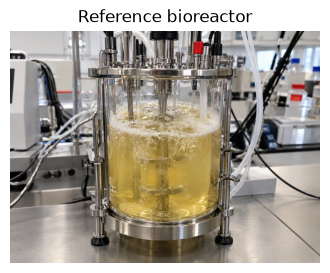

In [5]:
def resolve_reference_path(path_setting: str | Path) -> Path:
    """Absolute paths are used as-is; relative paths are resolved from the notebooks/ folder."""
    path = Path(path_setting).expanduser()
    return path if path.is_absolute() else (PROJECT_ROOT / "notebooks" / path).resolve()


def load_reference_image(path: Path) -> tuple[tuple[str, bytes, str], tuple[int, int]]:
    """Validate the reference photo and return it as an upload tuple for the OpenAI SDK.

    Returns ((filename, png_bytes, mime_type), (width, height)).
    """
    if not path.is_file():
        raise FileNotFoundError(
            f"Reference image not found: {path}\n"
            "Place your bioreactor photo there or update REFERENCE_IMAGE_PATH."
        )
    with Image.open(path) as img:
        img.verify()  # raises if the file is corrupted
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
    if max(img.size) > REFERENCE_MAX_EDGE:
        img.thumbnail((REFERENCE_MAX_EDGE, REFERENCE_MAX_EDGE), Image.Resampling.LANCZOS)
    buffer = io.BytesIO()
    img.save(buffer, format="PNG")
    png_bytes = buffer.getvalue()
    if len(png_bytes) >= 50 * 1024 * 1024:
        raise ValueError("The reference image must be smaller than 50 MB; please resize it.")
    return ("bioreactor_reference.png", png_bytes, "image/png"), img.size


def resolve_output_size(requested: str, model: str, reference_size: tuple[int, int] | None) -> str | None:
    """Turn IMAGE_SIZE into a concrete size string for the API.

    "match_reference" keeps the reference photo's aspect ratio so the framing is not distorted.
    """
    if requested != "match_reference":
        return requested
    if reference_size is None:
        return None
    width, height = reference_size
    aspect = width / height
    if model.startswith(ARBITRARY_SIZE_MODEL_PREFIXES):
        aspect = min(max(aspect, 1 / 3), 3)  # API limit: aspect ratio between 1:3 and 3:1
        long_edge = 1536
        if aspect >= 1:
            return f"{long_edge}x{round(long_edge / aspect / 16) * 16}"
        return f"{round(long_edge * aspect / 16) * 16}x{long_edge}"
    standard_sizes = {"1024x1024": 1.0, "1536x1024": 1.5, "1024x1536": 2 / 3}
    return min(standard_sizes, key=lambda size: abs(math.log(standard_sizes[size] / aspect)))


reference_path = resolve_reference_path(REFERENCE_IMAGE_PATH)
reference_file: tuple[str, bytes, str] | None = None
reference_size: tuple[int, int] | None = None
try:
    reference_file, reference_size = load_reference_image(reference_path)
except FileNotFoundError:
    if RUN_MODE != "dry_run":
        raise
    logger.warning("Reference image not found at %s — fine for a dry run, required for test/full.", reference_path)

OUTPUT_SIZE = resolve_output_size(IMAGE_SIZE, MODEL, reference_size)
if reference_file:
    logger.info("Reference image: %s (%dx%d) → output size %s", reference_path.name, *reference_size, OUTPUT_SIZE)
    fig, ax = plt.subplots(figsize=(4, 5))
    ax.imshow(Image.open(io.BytesIO(reference_file[1])))
    ax.set_title("Reference bioreactor")
    ax.axis("off")
    plt.show()

## 5. Visual scenarios, prompts and the generation plan

### Why scenario-based splitting?

Synthetic images made from the same reference and similar prompts can be near-identical. If two images of the
same operating condition land in *train* and *test*, the test score measures memorization, not generalization.

So the split is decided per **scenario** before any API call:

- A **scenario** is one complete operating condition: liquid level, medium color, turbidity, agitation,
  lighting, foam class, foam pattern and bubble size.
- The **leakage unit** is the *liquid condition* = **liquid level × medium color × turbidity**. Every scenario
  gets a liquid condition that **no other scenario uses**, so no condition can appear in two splits.
- All images of a scenario stay in that scenario's split.
- Within each (split, class) group, liquid levels, turbidities, colors, agitation, lighting and foam patterns
  are spread as evenly as possible, so validation and test cover the same *range* of conditions as training
  without sharing any concrete condition with it.

| Split | Scenarios per class | Images per scenario | Images per class | Scenarios total |
|---|---:|---:|---:|---:|
| train | 5 | 3 | 15 | 20 |
| validation | 5 | 1 | 5 | 20 |
| test | 5 | 1 | 5 | 20 |

Training gets 3 shots per scenario (natural shot-to-shot variation). Validation and test use one image per
scenario, which maximizes the number of *independent* conditions they measure.

The plan is deterministic (`RANDOM_SEED`) and saved to `metadata/generation_plan.csv`. Once images exist,
the notebook refuses to continue with a different plan, so images can never move between splits.

### 5.1 Scenario vocabulary

In [6]:
LIQUID_LEVELS = {
    "low_150ml": "low fill, about 150 mL — the liquid surface sits low in the vessel, well below its midpoint",
    "medium_low_225ml": "medium-low fill, about 225 mL — the liquid surface is a little below the vessel midpoint",
    "medium_300ml": "medium fill, about 300 mL — the liquid surface is around the vessel midpoint",
    "medium_high_350ml": "medium-high fill, about 350 mL — the liquid surface is clearly above the midpoint",
    "high_400ml": "high fill, about 400 mL — near the maximum working volume, with headspace still visible",
}

LIQUID_COLORS = {
    "pale_straw": "pale straw-yellow cell culture medium (acidified phenol red)",
    "golden_yellow": "golden-yellow culture medium",
    "amber": "amber, light-brown fermentation broth (yeast-extract based)",
    "light_orange": "light orange cell culture medium",
    "orange_red": "orange-red cell culture medium (phenol red near neutral pH)",
    "cherry_red": "cherry-red cell culture medium (fresh phenol-red medium)",
    "light_pink": "light pink cell culture medium",
    "magenta_pink": "magenta-pink cell culture medium (slightly alkaline phenol red)",
    "tan_beige": "tan/beige microbial culture broth",
    "pale_green": "pale green microalgae culture",
}

TURBIDITY_LEVELS = {
    "clear": "clear and transparent — the stirrer and probes are sharply visible through the liquid",
    "slightly_hazy": "slightly hazy — internal parts visible but a little softened",
    "hazy": "noticeably hazy — internal parts visible only as soft shapes",
    "cloudy": "cloudy — internal parts barely visible through the liquid",
    "dense_opaque": "dense and opaque, like a high-cell-density culture — nothing visible through the liquid",
}

AGITATION_LEVELS = {
    "still": "no agitation, the liquid is at rest",
    "gentle": "gentle stirring, a faint swirl on the surface",
    "moderate": "moderate stirring, a visible shallow vortex and rippling surface",
    "vigorous": "vigorous stirring, a turbulent surface with a deeper vortex",
}
# Agitation overlaps between classes on purpose, so the model cannot use it as a shortcut for the label.
ALLOWED_AGITATION = {
    "no_foam": ["still", "gentle", "moderate"],
    "minimal_foam": ["still", "gentle", "moderate"],
    "moderate_foam": ["gentle", "moderate", "vigorous"],
    "heavy_foam": ["gentle", "moderate", "vigorous"],
}

LIGHTING_CONDITIONS = {
    "neutral_overhead": "neutral white overhead laboratory lighting",
    "slightly_warm": "slightly warm indoor lighting",
    "cool_daylight": "slightly cool daylight from a nearby window",
    "soft_diffuse": "soft, diffuse lighting with gentle reflections on the glass",
    "crisp_highlights": "bright lighting with a few crisp specular highlights on the glass",
}

FOAM_PATTERNS = {
    "no_foam": {
        "flat_calm": "perfectly calm, mirror-like liquid surface with a clean meniscus",
        "gentle_ripples": "gentle ripples across the surface, without any bubbles",
        "smooth_vortex": "a smooth, shallow vortex around the stirrer shaft, without bubbles or foam",
        "clean_meniscus": "a clean meniscus line at the glass wall with no bubble residue",
        "reflective_surface": "a bubble-free surface reflecting the room light",
    },
    "minimal_foam": {
        "wall_bubbles": "a few isolated small bubbles clinging to the glass wall at the meniscus",
        "shaft_cluster": "a small, sparse cluster of bubbles around the stirrer shaft",
        "broken_ring": "a thin, broken ring of tiny bubbles along part of the meniscus",
        "scattered_bubbles": "scattered individual bubbles dotting the surface",
        "probe_bubbles": "a few bubbles gathered around the probes or dip tubes where they enter the liquid",
    },
    "moderate_foam": {
        "half_cover": "a foam layer covering roughly half of the liquid surface",
        "wall_ring": "a continuous foam ring about 1-2 cm wide around the vessel wall with an open liquid centre",
        "patchy_islands": "several foam islands spread across the surface with liquid visible between them",
        "thin_blanket": "a thin, mostly continuous foam blanket a few millimetres thick with open gaps",
        "shaft_collar": "a foam collar around the stirrer shaft and probes extending over part of the surface",
    },
    "heavy_foam": {
        "full_thick": "a thick, dense foam layer covering the entire surface, several centimetres tall",
        "rising_column": "foam rising well above the liquid and filling a large part of the headspace",
        "near_headplate": "foam that has climbed close to the headplate, filling the upper vessel",
        "wall_climb": "dense foam covering the whole surface and climbing up the inner glass walls",
        "layered_foam": "a tall foam layer with wetter, denser foam at the bottom and coarser, drier foam on top",
    },
}

BUBBLE_SIZES = {
    "none": "no bubbles",
    "fine": "mostly fine, small bubbles",
    "mixed": "a mix of small and medium bubbles",
    "coarse": "mostly larger, coarse bubbles",
}

SHOT_VARIATIONS = [
    "Capture the operating condition exactly as described.",
    "The same operating condition photographed a few seconds later: only natural, small differences in "
    "liquid surface motion, reflections and (where present) the exact arrangement of bubbles and foam.",
    "The same operating condition photographed a little later again: only natural, small differences in "
    "surface motion, light reflections on the glass and (where present) bubble and foam arrangement.",
]

print(
    f"{len(LIQUID_LEVELS)} levels × {len(LIQUID_COLORS)} colors × {len(TURBIDITY_LEVELS)} turbidities = "
    f"{len(LIQUID_LEVELS) * len(LIQUID_COLORS) * len(TURBIDITY_LEVELS)} possible liquid conditions"
)

5 levels × 10 colors × 5 turbidities = 250 possible liquid conditions


### 5.2 Prompt construction

In [7]:
def describe_operating_condition(row: dict[str, Any]) -> str:
    """Human-readable description of one scenario's operating condition."""
    return "\n".join([
        f"- Liquid level: {LIQUID_LEVELS[row['liquid_level']]}",
        f"- Culture medium color: {LIQUID_COLORS[row['liquid_color']]}",
        f"- Turbidity: {TURBIDITY_LEVELS[row['turbidity']]}",
        f"- Agitation: {AGITATION_LEVELS[row['agitation']]}",
        f"- Liquid surface and foam: {FOAM_PATTERNS[row['foam_class']][row['foam_pattern']]}",
        f"- Bubble size: {BUBBLE_SIZES[row['bubble_size']]}",
        f"- Lighting: {LIGHTING_CONDITIONS[row['lighting']]}",
    ])


def build_prompt(row: dict[str, Any]) -> str:
    """Combine base prompt, reference preservation, foam class, scenario and shot variation."""
    sections = [
        BASE_IMAGE_PROMPT.strip(),
        "REFERENCE IMAGE PRESERVATION:\n" + REFERENCE_PRESERVATION_PROMPT.strip(),
        "FOAM LEVEL:\n" + FOAM_CLASS_PROMPTS[row["foam_class"]].strip(),
        "OPERATING CONDITION:\n" + describe_operating_condition(row),
        "CAPTURE:\n" + SHOT_VARIATIONS[(int(row["shot_index"]) - 1) % len(SHOT_VARIATIONS)],
        "AVOID:\n" + NEGATIVE_PROMPT.strip(),
    ]
    return "\n\n".join(section for section in sections if section)

### 5.3 Build, validate and save the generation plan

In [8]:
def spread_evenly(values: list[str], n: int, rng: random.Random) -> list[str]:
    """Pick n values, using every value once before any value repeats (order shuffled)."""
    picked: list[str] = []
    while len(picked) < n:
        chunk = list(values)
        rng.shuffle(chunk)
        picked.extend(chunk)
    return picked[:n]


def pick_unused_liquid_condition(
    level: str, color: str, turbidity: str, used: set[tuple[str, str, str]], rng: random.Random
) -> tuple[str, str, str]:
    """Return (level, color, turbidity), changing the color (or, if needed, everything) until unused."""
    other_colors = [c for c in LIQUID_COLORS if c != color]
    rng.shuffle(other_colors)
    all_conditions = list(itertools.product(LIQUID_LEVELS, LIQUID_COLORS, TURBIDITY_LEVELS))
    rng.shuffle(all_conditions)
    candidates = [(level, color, turbidity)] + [(level, c, turbidity) for c in other_colors] + all_conditions
    for condition in candidates:
        if condition not in used:
            used.add(condition)
            return condition
    raise ValueError("Not enough distinct liquid conditions for the requested number of scenarios.")


def build_scenarios(seed: int) -> pd.DataFrame:
    """Create every visual scenario and assign it to a split — deterministic for a given seed."""
    rng = random.Random(seed)
    used_conditions: set[tuple[str, str, str]] = set()
    scenarios = []
    for split in SPLITS:
        n = SPLIT_DESIGN[split]["scenarios_per_class"]
        for foam_class in FOAM_CLASSES:
            levels = spread_evenly(list(LIQUID_LEVELS), n, rng)
            colors = spread_evenly(list(LIQUID_COLORS), n, rng)
            turbidities = spread_evenly(list(TURBIDITY_LEVELS), n, rng)
            agitations = spread_evenly(ALLOWED_AGITATION[foam_class], n, rng)
            lightings = spread_evenly(list(LIGHTING_CONDITIONS), n, rng)
            patterns = spread_evenly(list(FOAM_PATTERNS[foam_class]), n, rng)
            bubble_sizes = ["none"] * n if foam_class == "no_foam" else spread_evenly(["fine", "mixed", "coarse"], n, rng)
            for i in range(n):
                level, color, turbidity = pick_unused_liquid_condition(
                    levels[i], colors[i], turbidities[i], used_conditions, rng
                )
                scenarios.append({
                    "scenario_id": f"S{len(scenarios) + 1:02d}",
                    "dataset_split": split,
                    "foam_class": foam_class,
                    "liquid_level": level,
                    "liquid_color": color,
                    "turbidity": turbidity,
                    "liquid_condition_id": f"{level}|{color}|{turbidity}",
                    "agitation": agitations[i],
                    "lighting": lightings[i],
                    "foam_pattern": patterns[i],
                    "bubble_size": bubble_sizes[i],
                    "images_in_scenario": SPLIT_DESIGN[split]["images_per_scenario"],
                })
    return pd.DataFrame(scenarios)


def build_manifest(scenarios: pd.DataFrame) -> pd.DataFrame:
    """Expand scenarios into one row per planned image, including the exact prompt."""
    rows = []
    for scenario in scenarios.to_dict("records"):
        for shot_index in range(1, scenario["images_in_scenario"] + 1):
            image_id = f"img_{len(rows) + 1:04d}"
            filename = f"{image_id}_{scenario['scenario_id']}.png"
            row = {
                "image_id": image_id,
                "filename": filename,
                "file_path": f"data/{scenario['dataset_split']}/{scenario['foam_class']}/{filename}",
                **scenario,
                "shot_index": shot_index,
            }
            row["generation_prompt"] = build_prompt(row)
            rows.append(row)
    columns = [
        "image_id", "filename", "file_path", "foam_class", "scenario_id", "dataset_split",
        "liquid_level", "liquid_color", "turbidity", "liquid_condition_id", "agitation", "lighting",
        "foam_pattern", "bubble_size", "images_in_scenario", "shot_index", "generation_prompt",
    ]
    return pd.DataFrame(rows)[columns]


def validate_manifest(plan: pd.DataFrame) -> list[str]:
    """Return a list of problems with the plan (an empty list means the plan is valid)."""
    problems = []
    if len(plan) != TOTAL_IMAGES:
        problems.append(f"Plan has {len(plan)} entries, expected {TOTAL_IMAGES}.")
    for column in ("image_id", "filename", "file_path"):
        if plan[column].duplicated().any():
            problems.append(f"Duplicated values in '{column}'.")

    expected_per_class = TOTAL_IMAGES // len(FOAM_CLASSES)
    for foam_class, count in plan["foam_class"].value_counts().reindex(FOAM_CLASSES, fill_value=0).items():
        if count != expected_per_class:
            problems.append(f"{foam_class}: {count} images, expected {expected_per_class}.")
    counts = pd.crosstab(plan["dataset_split"], plan["foam_class"]).reindex(index=SPLITS, columns=FOAM_CLASSES, fill_value=0)
    for split in SPLITS:
        for foam_class in FOAM_CLASSES:
            if counts.loc[split, foam_class] != IMAGES_PER_CLASS_PER_SPLIT[split]:
                problems.append(f"{split}/{foam_class}: {counts.loc[split, foam_class]} images, expected {IMAGES_PER_CLASS_PER_SPLIT[split]}.")

    for column in ("dataset_split", "foam_class", "liquid_condition_id"):
        spread = plan.groupby("scenario_id")[column].nunique()
        if (spread > 1).any():
            problems.append(f"Scenarios with more than one {column}: {list(spread[spread > 1].index)}")
    condition_splits = plan.groupby("liquid_condition_id")["dataset_split"].nunique()
    if (condition_splits > 1).any():
        problems.append(f"Liquid conditions shared across splits: {list(condition_splits[condition_splits > 1].index)}")
    condition_scenarios = plan.groupby("liquid_condition_id")["scenario_id"].nunique()
    if (condition_scenarios > 1).any():
        problems.append(f"Liquid conditions used by several scenarios: {list(condition_scenarios[condition_scenarios > 1].index)}")

    expected_path = "data/" + plan["dataset_split"] + "/" + plan["foam_class"] + "/" + plan["filename"]
    if not (plan["file_path"] == expected_path).all():
        problems.append("Some file paths do not match their split/class folder.")
    if (plan["generation_prompt"].str.len() > 32000).any():
        problems.append("Some prompts exceed the 32,000-character API limit.")
    return problems


def count_generated_files() -> int:
    """Number of PNG files currently in the data/ folder."""
    return sum(1 for _ in DATA_DIR.rglob("*.png")) if DATA_DIR.exists() else 0


def save_generation_plan(plan: pd.DataFrame) -> pd.DataFrame:
    """Save the plan, refusing to replace a different plan once images have been generated."""
    if PLAN_PATH.exists():
        saved = pd.read_csv(PLAN_PATH, dtype=str, keep_default_na=False)
        current = plan.astype(str)
        if saved.columns.tolist() == current.columns.tolist() and saved.equals(current):
            logger.info("Generation plan matches %s.", PLAN_PATH.name)
            return plan
        existing = count_generated_files()
        if existing:
            if saved.shape == current.shape and saved.columns.tolist() == current.columns.tolist():
                changed = [c for c in current.columns if not saved[c].equals(current[c])]
            else:
                changed = ["structure"]
            raise RuntimeError(
                f"The new plan differs from {PLAN_PATH.name} (changed: {', '.join(changed)}), but {existing} "
                "image(s) were already generated with the saved plan. Mixing plans would break the split "
                "guarantees.\n→ Restore the original settings (seed, prompts, scenario design), or set "
                "ARCHIVE_EXISTING_RUN = True to move the old run to archive/ and start fresh."
            )
        logger.info("Plan changed and no images exist yet — overwriting %s.", PLAN_PATH.name)
    plan.to_csv(PLAN_PATH, index=False)
    logger.info("Saved generation plan → %s", PLAN_PATH.relative_to(PROJECT_ROOT))
    return plan


scenarios = build_scenarios(RANDOM_SEED)
plan = build_manifest(scenarios)
plan_problems = validate_manifest(plan)
if plan_problems:
    raise ValueError("Generation plan is invalid:\n- " + "\n- ".join(plan_problems))
plan = save_generation_plan(plan)
logger.info("Plan valid: %d images, %d scenarios, %d unique liquid conditions.",
            len(plan), plan["scenario_id"].nunique(), plan["liquid_condition_id"].nunique())

20:55:05 | INFO    | Generation plan matches generation_plan.csv.
20:55:05 | INFO    | Plan valid: 100 images, 60 scenarios, 60 unique liquid conditions.


In [9]:
print("Images per split and class:")
display(pd.crosstab(plan["dataset_split"], plan["foam_class"], margins=True, margins_name="total")
        .reindex(index=SPLITS + ["total"], columns=FOAM_CLASSES + ["total"]))

print("Scenarios per split and class:")
display(pd.crosstab(scenarios["dataset_split"], scenarios["foam_class"]).reindex(index=SPLITS, columns=FOAM_CLASSES))

print("Liquid levels per split (scenarios) — each split covers the full range:")
display(pd.crosstab(scenarios["dataset_split"], scenarios["liquid_level"]).reindex(index=SPLITS))

print("First scenarios:")
display(scenarios.head(8))

if BASE_PROMPT_PLACEHOLDER in BASE_IMAGE_PROMPT:
    logger.warning("BASE_IMAGE_PROMPT still contains the placeholder — paste your prompt before test/full runs.")
print("\nExample final prompt (", plan.loc[0, "image_id"], "):\n", "-" * 80, "\n", plan.loc[0, "generation_prompt"], sep="")

Images per split and class:


foam_class,no_foam,minimal_foam,moderate_foam,heavy_foam,total
dataset_split,,,,,
train,15,15,15,15,60
validation,5,5,5,5,20
test,5,5,5,5,20
total,25,25,25,25,100


Scenarios per split and class:


foam_class,no_foam,minimal_foam,moderate_foam,heavy_foam
dataset_split,,,,
train,5,5,5,5
validation,5,5,5,5
test,5,5,5,5


Liquid levels per split (scenarios) — each split covers the full range:


liquid_level,high_400ml,low_150ml,medium_300ml,medium_high_350ml,medium_low_225ml
dataset_split,,,,,
train,4,4,4,4,4
validation,4,4,4,4,4
test,4,4,4,4,4


First scenarios:


,scenario_id,dataset_split,foam_class,liquid_level,liquid_color,turbidity,liquid_condition_id,agitation,lighting,foam_pattern,bubble_size,images_in_scenario
0,S01,train,no_foam,medium_high_350ml,tan_beige,slightly_hazy,medium_high_350ml|tan_beige|slightly_hazy,gentle,cool_daylight,gentle_ripples,none,3
1,S02,train,no_foam,medium_low_225ml,golden_yellow,hazy,medium_low_225ml|golden_yellow|hazy,moderate,slightly_warm,clean_meniscus,none,3
2,S03,train,no_foam,medium_300ml,magenta_pink,cloudy,medium_300ml|magenta_pink|cloudy,still,neutral_overhead,flat_calm,none,3
3,S04,train,no_foam,high_400ml,light_pink,dense_opaque,high_400ml|light_pink|dense_opaque,gentle,soft_diffuse,smooth_vortex,none,3
4,S05,train,no_foam,low_150ml,orange_red,clear,low_150ml|orange_red|clear,still,crisp_highlights,reflective_surface,none,3
5,S06,train,minimal_foam,high_400ml,tan_beige,clear,high_400ml|tan_beige|clear,moderate,neutral_overhead,broken_ring,mixed,3
6,S07,train,minimal_foam,medium_high_350ml,golden_yellow,slightly_hazy,medium_high_350ml|golden_yellow|slightly_hazy,gentle,crisp_highlights,shaft_cluster,fine,3
7,S08,train,minimal_foam,medium_low_225ml,pale_straw,dense_opaque,medium_low_225ml|pale_straw|dense_opaque,still,cool_daylight,probe_bubbles,coarse,3



Example final prompt (img_0001):
--------------------------------------------------------------------------------
A photorealistic, high-resolution photograph of a 500 mL benchtop laboratory bioreactor in a modern
bioprocess laboratory, photographed from outside the vessel at bench height. The bioreactor has a clear
borosilicate glass cylindrical vessel held in a polished stainless-steel frame with vertical support rods,
a stainless-steel base ring on black rubber feet, and a stainless-steel headplate carrying several ports,
sensor probes with black and red connectors, a central stirrer shaft with two flat-blade impellers, dip
tubes and translucent silicone tubing. The vessel stands on a brushed stainless-steel lab bench, with
softly out-of-focus laboratory equipment and reagent bottles in the background.

Style: realistic laboratory documentation photography, natural colors, accurate glass refraction and
reflections, sharp focus on the vessel and its contents, gentle background blur,

## 6. Image generation functions

- **API initialization** — reads `OPENAI_API_KEY` or asks with `getpass` (hidden input). The key is never
  printed or saved. The SDK's built-in retries are disabled so this notebook's own retry logic is visible.
- **Image generation** — one `client.images.edit` request per image, with the reference photo attached.
- **Retries** — rate limits, timeouts, connection problems and 5xx errors are retried with exponential
  backoff + jitter (honouring the server's `Retry-After` header). Invalid requests and safety rejections are
  not retried. Authentication, permission, missing-model and out-of-quota errors stop the run immediately.
- **Saving** — each image is checked with Pillow and written atomically (temporary file → rename), so an
  interruption can never leave a half-written PNG under the final name.
- **Resume** — before generating, existing files are checked. Valid images are **never regenerated or
  overwritten**; missing, corrupted or failed ones are generated again.

In [10]:
class FatalAPIError(RuntimeError):
    """An error that would make every following request fail too (bad key, no access, no quota)."""


def init_openai_client() -> OpenAI:
    """Create the OpenAI client from OPENAI_API_KEY or a hidden prompt. The key is never printed."""
    api_key = os.environ.get("OPENAI_API_KEY", "").strip()
    if not api_key:
        api_key = getpass("Enter your OpenAI API key (input is hidden): ").strip()
    if not api_key:
        raise ValueError("No API key provided.")
    client = OpenAI(api_key=api_key, max_retries=0, timeout=REQUEST_TIMEOUT_SECONDS)
    logger.info("OpenAI client initialized (key loaded from %s).",
                "environment" if os.environ.get("OPENAI_API_KEY") else "hidden prompt")
    return client


def describe_error(err: Exception) -> str:
    """Short, single-line error description with anything that looks like an API key redacted."""
    message = getattr(err, "message", None) or str(err)
    message = re.sub(r"sk-[A-Za-z0-9_\-*]{4,}", "sk-***", message)
    return f"{type(err).__name__}: {' '.join(message.split())[:300]}"


def request_image(
    client: OpenAI, prompt: str, reference_file: tuple[str, bytes, str], size: str | None
) -> tuple[bytes, dict[str, int]]:
    """Send one image-edit request (reference image + prompt) and return (image_bytes, token_usage)."""
    params: dict[str, Any] = {
        "model": MODEL,
        "image": reference_file,
        "prompt": prompt,
        "quality": IMAGE_QUALITY,
        "output_format": "png",
        "n": 1,
    }
    if size:
        params["size"] = size
    if INPUT_FIDELITY and MODEL in INPUT_FIDELITY_MODELS:
        params["input_fidelity"] = INPUT_FIDELITY
    response = client.images.edit(**params)
    if not response.data or not response.data[0].b64_json:
        raise ValueError("the API response contained no image data")
    usage = {}
    if getattr(response, "usage", None):
        usage = {"input_tokens": response.usage.input_tokens, "output_tokens": response.usage.output_tokens}
    return base64.b64decode(response.data[0].b64_json), usage


def backoff_delay(attempt: int, err: Exception | None) -> float:
    """Exponential backoff with jitter; respects a Retry-After header when the server sends one."""
    delay = min(MAX_BACKOFF_SECONDS, INITIAL_BACKOFF_SECONDS * 2 ** (attempt - 1))
    response = getattr(err, "response", None)
    if response is not None:
        try:
            delay = max(delay, float(response.headers.get("retry-after", "")))
        except ValueError:
            pass
    return delay * random.uniform(0.85, 1.15)


def check_image_bytes(image_bytes: bytes) -> None:
    """Raise if the bytes are not a complete, decodable image."""
    with Image.open(io.BytesIO(image_bytes)) as img:
        img.load()


def generate_with_retries(
    client: OpenAI, prompt: str, reference_file: tuple[str, bytes, str], size: str | None
) -> dict[str, Any]:
    """Generate one image, retrying temporary failures. Raises FatalAPIError for run-stopping errors."""
    start = time.monotonic()
    last_error, last_exception = "", None
    for attempt in range(1, MAX_ATTEMPTS_PER_IMAGE + 1):
        try:
            image_bytes, usage = request_image(client, prompt, reference_file, size)
            check_image_bytes(image_bytes)
            return {"ok": True, "image_bytes": image_bytes, "usage": usage, "attempts": attempt,
                    "error": "", "duration_s": time.monotonic() - start}
        except openai.AuthenticationError:
            raise FatalAPIError("Authentication failed — check your OpenAI API key.") from None
        except (openai.PermissionDeniedError, openai.NotFoundError) as err:
            raise FatalAPIError(
                f"{describe_error(err)} — check that your organization has access to {MODEL!r} "
                "(GPT Image models may require organization verification)."
            ) from None
        except openai.RateLimitError as err:
            if getattr(err, "code", None) == "insufficient_quota":
                raise FatalAPIError("Insufficient quota — add credits or raise your OpenAI usage limit.") from None
            last_error, last_exception, retryable = describe_error(err), err, True
        except (openai.APITimeoutError, openai.APIConnectionError, openai.InternalServerError) as err:
            last_error, last_exception, retryable = describe_error(err), err, True
        except openai.BadRequestError as err:
            # Invalid parameters or a safety rejection: repeating the identical request won't help.
            last_error, last_exception, retryable = describe_error(err), err, False
        except openai.APIStatusError as err:
            last_error, last_exception, retryable = describe_error(err), err, err.status_code == 409
        except (ValueError, OSError) as err:  # empty or undecodable image payload
            last_error, last_exception, retryable = f"Invalid image payload: {err}", err, True

        if not retryable or attempt == MAX_ATTEMPTS_PER_IMAGE:
            break
        delay = backoff_delay(attempt, last_exception)
        logger.warning("   attempt %d/%d failed (%s) — retrying in %.0fs", attempt, MAX_ATTEMPTS_PER_IMAGE, last_error, delay)
        time.sleep(delay)
    return {"ok": False, "image_bytes": None, "usage": {}, "attempts": attempt,
            "error": last_error, "duration_s": time.monotonic() - start}

In [11]:
METADATA_COLUMNS = [
    # required columns
    "image_id", "filename", "file_path", "foam_class", "scenario_id", "dataset_split",
    "liquid_level", "liquid_color", "turbidity", "foam_pattern", "generation_prompt",
    "model", "generated_at", "status",
    # additional scenario parameters and generation details
    "liquid_condition_id", "agitation", "lighting", "bubble_size", "shot_index",
    "requested_size", "quality", "input_fidelity", "width", "height", "attempts",
    "duration_s", "input_tokens", "output_tokens", "error", "note",
]


def save_image(image_bytes: bytes, destination: Path) -> tuple[int, int]:
    """Save the image as PNG at its native resolution (atomic write). Returns (width, height)."""
    with Image.open(io.BytesIO(image_bytes)) as img:
        img.load()
        size = img.size
        if img.format == "PNG":
            data = image_bytes
        else:
            buffer = io.BytesIO()
            img.save(buffer, format="PNG")
            data = buffer.getvalue()
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".part")
    temporary.write_bytes(data)
    os.replace(temporary, destination)
    return size


def image_is_readable(path: Path) -> bool:
    """True if the file exists and Pillow can fully decode it."""
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            img.load()
        return True
    except Exception:
        return False


def load_metadata() -> dict[str, dict[str, Any]]:
    """Load metadata.csv as {image_id: record}."""
    if not METADATA_PATH.exists():
        return {}
    frame = pd.read_csv(METADATA_PATH, dtype=str, keep_default_na=False)
    return {record["image_id"]: record for record in frame.to_dict("records")}


def write_metadata(records: dict[str, dict[str, Any]]) -> None:
    """Write all records to metadata.csv (atomic replace, sorted by image_id)."""
    frame = pd.DataFrame([records[key] for key in sorted(records)], columns=METADATA_COLUMNS)
    temporary = METADATA_PATH.with_name(METADATA_PATH.name + ".part")
    frame.to_csv(temporary, index=False)
    os.replace(temporary, METADATA_PATH)


def make_metadata_record(row: dict[str, Any], status: str, **details: Any) -> dict[str, Any]:
    """Build one metadata row from a plan row plus generation details."""
    record = {column: "" for column in METADATA_COLUMNS}
    record.update({column: row[column] for column in METADATA_COLUMNS if column in row})
    record.update({
        "model": MODEL,
        "status": status,
        "requested_size": OUTPUT_SIZE or "",
        "quality": IMAGE_QUALITY,
        "input_fidelity": INPUT_FIDELITY if MODEL in INPUT_FIDELITY_MODELS else "",
    })
    record.update(details)
    return record


def reconcile_with_disk(plan: pd.DataFrame, records: dict[str, dict[str, Any]]) -> dict[str, dict[str, Any]]:
    """Make metadata agree with the files on disk (the files are the source of truth for resuming)."""
    for row in plan.to_dict("records"):
        path = PROJECT_ROOT / row["file_path"]
        record = records.get(row["image_id"])
        recorded_success = record is not None and record["status"] == "success"
        if path.exists() and image_is_readable(path):
            if not recorded_success:
                with Image.open(path) as img:
                    width, height = img.size
                records[row["image_id"]] = make_metadata_record(
                    row, "success", width=width, height=height,
                    generated_at=datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(timespec="seconds"),
                    note="recovered: valid file found on disk without a success record",
                )
        elif recorded_success:
            records[row["image_id"]] = {**record, "status": "missing",
                                        "error": "file missing or unreadable — will be regenerated"}
    for leftover in DATA_DIR.rglob("*.part"):
        leftover.unlink()  # unfinished temporary files from an interrupted write
    return records


def select_images_to_generate(plan: pd.DataFrame, records: dict[str, dict[str, Any]], run_mode: str) -> list[dict[str, Any]]:
    """All images without a successful record; in test mode, TEST_IMAGE_COUNT of them spread across classes."""
    pending = [row for row in plan.to_dict("records")
               if records.get(row["image_id"], {}).get("status") != "success"]
    if run_mode != "test":
        return pending
    by_class = {c: [row for row in pending if row["foam_class"] == c] for c in FOAM_CLASSES}
    selected: list[dict[str, Any]] = []
    while len(selected) < TEST_IMAGE_COUNT and any(by_class.values()):
        for foam_class in FOAM_CLASSES:
            if by_class[foam_class] and len(selected) < TEST_IMAGE_COUNT:
                selected.append(by_class[foam_class].pop(0))
    return selected

In [12]:
def run_generation(
    client: OpenAI, plan: pd.DataFrame, reference_file: tuple[str, bytes, str], size: str | None, run_mode: str
) -> dict[str, Any]:
    """Generate the selected images strictly one at a time, saving image + metadata after each one."""
    records = reconcile_with_disk(plan, load_metadata())
    write_metadata(records)
    queue = select_images_to_generate(plan, records, run_mode)
    stats = {"images_attempted": 0, "succeeded": 0, "failed": 0, "api_requests": 0, "retries": 0,
             "estimated_cost_usd": 0.0, "input_tokens": 0, "output_tokens": 0, "stopped_early": ""}
    if not queue:
        logger.info("Nothing to generate — all %d planned images already exist.", len(plan))
        return stats

    logger.info("Generating %d image(s) sequentially | model=%s size=%s quality=%s",
                len(queue), MODEL, size or "default", IMAGE_QUALITY)
    consecutive_failures = 0
    try:
        for position, row in enumerate(queue, start=1):
            if (ESTIMATED_BUDGET_LIMIT_USD is not None
                    and stats["estimated_cost_usd"] + ESTIMATED_COST_PER_IMAGE_USD > ESTIMATED_BUDGET_LIMIT_USD):
                stats["stopped_early"] = "estimated budget limit reached"
                logger.warning("Stopping: the next image would exceed ESTIMATED_BUDGET_LIMIT_USD = $%.2f.",
                               ESTIMATED_BUDGET_LIMIT_USD)
                break

            result = generate_with_retries(client, row["generation_prompt"], reference_file, size)
            stats["images_attempted"] += 1
            stats["api_requests"] += result["attempts"]
            stats["retries"] += result["attempts"] - 1

            if result["ok"]:
                width, height = save_image(result["image_bytes"], PROJECT_ROOT / row["file_path"])
                records[row["image_id"]] = make_metadata_record(
                    row, "success", width=width, height=height, attempts=result["attempts"],
                    duration_s=round(result["duration_s"], 1),
                    generated_at=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                    input_tokens=result["usage"].get("input_tokens", ""),
                    output_tokens=result["usage"].get("output_tokens", ""),
                )
                stats["succeeded"] += 1
                stats["estimated_cost_usd"] += ESTIMATED_COST_PER_IMAGE_USD
                stats["input_tokens"] += result["usage"].get("input_tokens", 0)
                stats["output_tokens"] += result["usage"].get("output_tokens", 0)
                consecutive_failures = 0
                outcome = "✓"
            else:
                records[row["image_id"]] = make_metadata_record(
                    row, "failed", attempts=result["attempts"], duration_s=round(result["duration_s"], 1),
                    generated_at=datetime.now(timezone.utc).isoformat(timespec="seconds"), error=result["error"],
                )
                stats["failed"] += 1
                consecutive_failures += 1
                outcome = f"✗ {result['error']}"
            write_metadata(records)

            dataset_done = sum(1 for r in records.values() if r["status"] == "success")
            logger.info("[%3d/%d] %s %-10s %-13s %s | %d attempt(s), %.0fs | dataset %d/%d | est. cost this run $%.2f",
                        position, len(queue), row["image_id"], row["dataset_split"], row["foam_class"], outcome,
                        result["attempts"], result["duration_s"], dataset_done, len(plan), stats["estimated_cost_usd"])

            if consecutive_failures >= MAX_CONSECUTIVE_FAILURES:
                stats["stopped_early"] = f"{consecutive_failures} consecutive failures"
                logger.error("Stopping after %d consecutive failures — check the errors above.", consecutive_failures)
                break
            if position < len(queue):
                time.sleep(PAUSE_BETWEEN_REQUESTS_SECONDS)
    except FatalAPIError as err:
        stats["stopped_early"] = str(err)
        logger.error("Run stopped: %s", err)
    except KeyboardInterrupt:
        stats["stopped_early"] = "interrupted by user"
        logger.warning("Interrupted. Progress is saved — rerun the generation cell to resume.")
    finally:
        write_metadata(records)
    return stats

## 7. Cost estimate and run plan

All amounts are **estimates** based on `ESTIMATED_COST_PER_IMAGE_USD` — they are *not* your billed usage.
Retries of failed requests are counted separately; failed requests are usually not billed, so the estimate
only counts successful images. Check actual charges on the OpenAI usage dashboard.

In [13]:
def estimate_cost(n_images: int) -> float:
    """Estimated cost (USD) of generating n_images successful images."""
    return n_images * ESTIMATED_COST_PER_IMAGE_USD


records_now = reconcile_with_disk(plan, load_metadata())
already_done = sum(1 for r in records_now.values() if r["status"] == "success")
remaining = len(plan) - already_done
this_run = len(select_images_to_generate(plan, records_now, RUN_MODE)) if RUN_MODE != "dry_run" else 0

cost_table = pd.DataFrame([
    ("Model / size / quality", f"{MODEL} / {OUTPUT_SIZE or IMAGE_SIZE} / {IMAGE_QUALITY}"),
    ("Images in plan", len(plan)),
    ("Already generated (valid files)", already_done),
    ("Still missing", remaining),
    (f"To generate in this run ({RUN_MODE})", this_run),
    ("Expected API calls this run", f"{this_run} (up to {this_run * MAX_ATTEMPTS_PER_IMAGE} with retries)"),
    ("Estimated cost per image", f"${ESTIMATED_COST_PER_IMAGE_USD:.3f}"),
    ("Estimated cost of this run", f"${estimate_cost(this_run):.2f}"),
    ("Estimated cost of all missing images", f"${estimate_cost(remaining):.2f}"),
    ("Estimated cost of the full 100-image dataset", f"${estimate_cost(len(plan)):.2f}"),
    ("Budget limit per run", "none" if ESTIMATED_BUDGET_LIMIT_USD is None else f"${ESTIMATED_BUDGET_LIMIT_USD:.2f}"),
], columns=["item", "value (ESTIMATE)"])
display(cost_table)

,item,value (ESTIMATE)
0,Model / size / quality,gpt-image-2 / 1536x1152 / low
1,Images in plan,100
2,Already generated (valid files),4
3,Still missing,96
4,To generate in this run (full),96
5,Expected API calls this run,96 (up to 480 with retries)
6,Estimated cost per image,$0.250
7,Estimated cost of this run,$24.00
8,Estimated cost of all missing images,$24.00
9,Estimated cost of the full 100-image dataset,$25.00


## 8. Generate images

- `dry_run`: nothing is sent to OpenAI.
- `test` / `full`: requests your API key (unless `OPENAI_API_KEY` is set), then generates images one at a time.

**Interrupted?** Just run this cell again (or Run All). Valid images are kept and skipped; only missing or
failed images are generated. A `full` run that hit the budget limit or a temporary outage can be resumed the
same way.

In [14]:
def check_ready_for_generation() -> None:
    """Stop before spending money if something required is missing."""
    if not BASE_IMAGE_PROMPT.strip() or BASE_PROMPT_PLACEHOLDER in BASE_IMAGE_PROMPT:
        raise ValueError("Paste your prompt into BASE_IMAGE_PROMPT (Section 2.1) before generating images.")
    if reference_file is None:
        raise ValueError(f"Reference image missing: {reference_path}")


generation_stats = None
if RUN_MODE == "dry_run":
    print("DRY RUN — no API key requested, no API calls made, no cost incurred.")
    print(f"Review {PLAN_PATH.relative_to(PROJECT_ROOT)}, then set RUN_MODE = 'test' to try a few images.")
else:
    check_ready_for_generation()
    client = init_openai_client()
    generation_stats = run_generation(client, plan, reference_file, OUTPUT_SIZE, RUN_MODE)
    print("\nRun summary (cost is an ESTIMATE, not billed usage):")
    display(pd.Series(generation_stats, name="value").to_frame())

Enter your OpenAI API key (input is hidden):  ········


20:55:08 | INFO    | OpenAI client initialized (key loaded from hidden prompt).
20:55:08 | INFO    | Generating 96 image(s) sequentially | model=gpt-image-2 size=1536x1152 quality=low
20:55:22 | INFO    | HTTP Request: POST https://api.openai.com/v1/images/edits "HTTP/1.1 200 OK"
20:55:22 | INFO    | [  1/96] img_0002 train      no_foam       ✓ | 1 attempt(s), 14s | dataset 5/100 | est. cost this run $0.25
20:55:34 | INFO    | HTTP Request: POST https://api.openai.com/v1/images/edits "HTTP/1.1 200 OK"
20:55:34 | INFO    | [  2/96] img_0003 train      no_foam       ✓ | 1 attempt(s), 11s | dataset 6/100 | est. cost this run $0.50
20:55:48 | INFO    | HTTP Request: POST https://api.openai.com/v1/images/edits "HTTP/1.1 200 OK"
20:55:48 | INFO    | [  3/96] img_0004 train      no_foam       ✓ | 1 attempt(s), 14s | dataset 7/100 | est. cost this run $0.75
20:56:04 | INFO    | HTTP Request: POST https://api.openai.com/v1/images/edits "HTTP/1.1 200 OK"
20:56:05 | INFO    | [  4/96] img_0005 tr

,value
images_attempted,96
succeeded,96
failed,0
api_requests,96
retries,0
estimated_cost_usd,24.0
input_tokens,212321
output_tokens,17376
stopped_early,


## 9. Dataset validation

Checks that the dataset matches the plan and the requirements: 100 successful images, 25 per class,
60/20/20 split with 15/5/5 per class, unique IDs, no scenario or liquid condition in more than one split,
no images moved between splits, no missing, corrupted or stray files, and no exact duplicates.

**Similarity check (optional).** Every image gets a 256-bit *difference hash* (dHash) and all pairs are
compared. Pairs from **different splits** whose hashes differ in ≤ `SIMILARITY_THRESHOLD` of their bits are
flagged for **manual review** — nothing is ever deleted automatically.

> ⚠️ Perceptual hashing is only a basic quality check. Because every image shows the same vessel and
> background, hashes are naturally close; and two images can be semantically near-identical while their
> hashes differ. It **does not guarantee** the absence of data leakage — the scenario-based plan is the real
> protection. To calibrate the threshold, compare against the *within-scenario* distances reported below
> (training shots of the same scenario are the closest pairs you'd expect).

In [15]:
def file_sha256(path: Path) -> str:
    """SHA-256 of a file's bytes (exact-duplicate detection)."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


def difference_hash(path: Path, hash_size: int = HASH_SIZE) -> np.ndarray:
    """dHash: compare neighbouring pixels of a small grayscale thumbnail → boolean array of hash_size² bits."""
    with Image.open(path) as img:
        small = img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()


def compute_similarity_pairs(images: pd.DataFrame) -> pd.DataFrame:
    """Normalized Hamming distance between the dHashes of every pair of images."""
    images = images.reset_index(drop=True)
    if len(images) < 2:
        return pd.DataFrame(columns=["image_a", "image_b", "split_a", "split_b", "scenario_a", "scenario_b",
                                     "distance", "cross_split", "same_scenario"])
    hashes = np.stack([difference_hash(PROJECT_ROOT / p) for p in images["file_path"]])
    distances = (hashes[:, None, :] != hashes[None, :, :]).mean(axis=2)
    a, b = np.triu_indices(len(images), k=1)
    pairs = pd.DataFrame({
        "image_a": images["image_id"].to_numpy()[a], "image_b": images["image_id"].to_numpy()[b],
        "split_a": images["dataset_split"].to_numpy()[a], "split_b": images["dataset_split"].to_numpy()[b],
        "scenario_a": images["scenario_id"].to_numpy()[a], "scenario_b": images["scenario_id"].to_numpy()[b],
        "distance": distances[a, b].round(4),
    })
    pairs["cross_split"] = pairs["split_a"] != pairs["split_b"]
    pairs["same_scenario"] = pairs["scenario_a"] == pairs["scenario_b"]
    return pairs.sort_values("distance").reset_index(drop=True)


def validate_dataset(plan: pd.DataFrame, records: dict[str, dict[str, Any]]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run all dataset checks. Returns (report, similarity_pairs)."""
    report: list[dict[str, str]] = []

    def add(check: str, status: str, details: str) -> None:
        report.append({"check": check, "status": status, "details": details})

    meta = pd.DataFrame(list(records.values()), columns=METADATA_COLUMNS)
    ok = meta[meta["status"] == "success"].copy()

    # Generation results
    add("successful_images", "PASS" if len(ok) == TOTAL_IMAGES else "FAIL", f"{len(ok)}/{TOTAL_IMAGES} images generated")
    for record in meta[meta["status"] != "success"].to_dict("records"):
        add("generation_failure", "FAIL", f"{record['image_id']} ({record['status']}): {record['error']}")
    never_attempted = sorted(set(plan["image_id"]) - set(meta["image_id"]))
    if never_attempted:
        add("not_attempted", "FAIL", f"{len(never_attempted)} planned image(s) not attempted yet")

    # Class and split distribution
    expected_per_class = TOTAL_IMAGES // len(FOAM_CLASSES)
    for foam_class in FOAM_CLASSES:
        n = int((ok["foam_class"] == foam_class).sum())
        add("class_count", "PASS" if n == expected_per_class else "FAIL", f"{foam_class}: {n}/{expected_per_class}")
    for split in SPLITS:
        expected = IMAGES_PER_CLASS_PER_SPLIT[split] * len(FOAM_CLASSES)
        n = int((ok["dataset_split"] == split).sum())
        add("split_count", "PASS" if n == expected else "FAIL", f"{split}: {n}/{expected}")
    matrix = pd.crosstab(ok["dataset_split"], ok["foam_class"]).reindex(index=SPLITS, columns=FOAM_CLASSES, fill_value=0)
    wrong_cells = [f"{s}/{c}={matrix.loc[s, c]} (expected {IMAGES_PER_CLASS_PER_SPLIT[s]})"
                   for s in SPLITS for c in FOAM_CLASSES if matrix.loc[s, c] != IMAGES_PER_CLASS_PER_SPLIT[s]]
    add("split_class_distribution", "FAIL" if wrong_cells else "PASS", "; ".join(wrong_cells) or "15/5/5 per class")

    # Identifiers and plan consistency
    on_disk_meta = pd.read_csv(METADATA_PATH, dtype=str, keep_default_na=False) if METADATA_PATH.exists() else meta
    duplicated_ids = on_disk_meta["image_id"][on_disk_meta["image_id"].duplicated()].tolist()
    add("unique_image_ids", "FAIL" if duplicated_ids else "PASS", ", ".join(duplicated_ids) or "all unique")
    planned = plan.set_index("image_id")
    moved = [r["image_id"] for r in ok.to_dict("records")
             if r["image_id"] not in planned.index
             or (r["dataset_split"], r["foam_class"], r["scenario_id"], r["file_path"])
             != tuple(planned.loc[r["image_id"], ["dataset_split", "foam_class", "scenario_id", "file_path"]])]
    add("matches_generation_plan", "FAIL" if moved else "PASS", ", ".join(moved) or "split/class/scenario unchanged")

    # Leakage
    for unit in ("scenario_id", "liquid_condition_id"):
        n_splits = ok.groupby(unit)["dataset_split"].nunique()
        leaking = n_splits[n_splits > 1].index.tolist()
        add(f"{unit}_leakage", "FAIL" if leaking else "PASS", ", ".join(leaking) or f"each {unit} is in exactly one split")

    # Files
    missing = [r["image_id"] for r in ok.to_dict("records") if not (PROJECT_ROOT / r["file_path"]).exists()]
    corrupted = [r["image_id"] for r in ok.to_dict("records")
                 if (PROJECT_ROOT / r["file_path"]).exists() and not image_is_readable(PROJECT_ROOT / r["file_path"])]
    add("missing_files", "FAIL" if missing else "PASS", ", ".join(missing) or "none")
    add("corrupted_images", "FAIL" if corrupted else "PASS", ", ".join(corrupted) or "none")
    planned_paths = set(plan["file_path"])
    stray = sorted(p.relative_to(PROJECT_ROOT).as_posix() for p in DATA_DIR.rglob("*")
                   if p.is_file() and p.name != ".DS_Store" and p.relative_to(PROJECT_ROOT).as_posix() not in planned_paths)
    add("unexpected_files", "WARN" if stray else "PASS", ", ".join(stray[:20]) or "none")

    # Duplicates
    readable = ok[~ok["image_id"].isin(missing + corrupted)]
    ids_by_sha: dict[str, list[str]] = {}
    for r in readable.to_dict("records"):
        ids_by_sha.setdefault(file_sha256(PROJECT_ROOT / r["file_path"]), []).append(r["image_id"])
    duplicate_groups = [ids for ids in ids_by_sha.values() if len(ids) > 1]
    add("exact_duplicates", "WARN" if duplicate_groups else "PASS", str(duplicate_groups) if duplicate_groups else "none")

    pairs = compute_similarity_pairs(readable) if RUN_SIMILARITY_CHECK else compute_similarity_pairs(readable.iloc[:0])
    if not RUN_SIMILARITY_CHECK:
        add("cross_split_similarity", "INFO", "similarity check disabled")
    elif pairs.empty:
        add("cross_split_similarity", "INFO", "not enough images to compare")
    else:
        within = pairs.loc[pairs["same_scenario"], "distance"]
        cross = pairs.loc[pairs["cross_split"], "distance"]
        if not within.empty:
            add("similarity_calibration", "INFO",
                f"within-scenario distance: min {within.min():.3f}, median {within.median():.3f}")
        if not cross.empty:
            add("similarity_calibration", "INFO", f"closest cross-split pair distance: {cross.min():.3f}")
        flagged = pairs[pairs["cross_split"] & (pairs["distance"] <= SIMILARITY_THRESHOLD)]
        for p in flagged.to_dict("records"):
            add("cross_split_similarity", "WARN",
                f"{p['image_a']} ({p['split_a']}) ~ {p['image_b']} ({p['split_b']}): distance {p['distance']:.3f} — review manually")
        if flagged.empty:
            add("cross_split_similarity", "PASS", f"no cross-split pair with distance ≤ {SIMILARITY_THRESHOLD}")

    return pd.DataFrame(report), pairs


records = reconcile_with_disk(plan, load_metadata())
write_metadata(records)
validation_report, similarity_pairs = validate_dataset(plan, records)
validation_report.to_csv(VALIDATION_REPORT_PATH, index=False)
logger.info("Saved validation report → %s", VALIDATION_REPORT_PATH.relative_to(PROJECT_ROOT))
display(validation_report["status"].value_counts().rename("checks").to_frame())

21:17:44 | INFO    | Saved validation report → metadata/validation_report.csv


,checks
status,
WARN,1815
PASS,17
INFO,2


## 10. Dataset visualization

In [16]:
def successful_images(records: dict[str, dict[str, Any]]) -> pd.DataFrame:
    """Metadata rows of successfully generated images as a DataFrame."""
    meta = pd.DataFrame(list(records.values()), columns=METADATA_COLUMNS)
    return meta[meta["status"] == "success"].sort_values("image_id").reset_index(drop=True)


def show_dataset_summary(images: pd.DataFrame) -> None:
    """Image counts per foam class and split (generated vs. planned)."""
    generated = (pd.crosstab(images["foam_class"], images["dataset_split"], margins=True, margins_name="total")
                 if not images.empty else pd.DataFrame())
    generated = generated.reindex(index=FOAM_CLASSES + ["total"], columns=SPLITS + ["total"], fill_value=0)
    print("Generated images per class and split:")
    display(generated)
    planned = pd.crosstab(plan["foam_class"], plan["dataset_split"], margins=True, margins_name="total")
    print("Planned:")
    display(planned.reindex(index=FOAM_CLASSES + ["total"], columns=SPLITS + ["total"]))


def show_image_grid(rows: list[list[dict[str, Any]]], row_labels: list[str], caption: Any, title: str) -> None:
    """Draw a grid of thumbnails; rows is a list of lists of metadata records."""
    n_cols = max((len(r) for r in rows), default=0)
    if n_cols == 0:
        print(f"{title}: no images yet.")
        return
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(3.2 * n_cols, 4.0 * len(rows)), squeeze=False)
    for r, (records_in_row, label) in enumerate(zip(rows, row_labels)):
        for c in range(n_cols):
            ax = axes[r][c]
            ax.axis("off")
            if c < len(records_in_row):
                record = records_in_row[c]
                with Image.open(PROJECT_ROOT / record["file_path"]) as img:
                    img.thumbnail((512, 512))
                    ax.imshow(img.copy())
                ax.set_title(caption(record), fontsize=8)
        axes[r][0].text(-0.08, 0.5, label, transform=axes[r][0].transAxes, rotation=90,
                        va="center", ha="right", fontsize=11, fontweight="bold")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


def show_class_gallery(images: pd.DataFrame, per_class: int = 4) -> None:
    """Representative images of each foam class, taken from different scenarios and splits."""
    rows = []
    for foam_class in FOAM_CLASSES:
        candidates = images[images["foam_class"] == foam_class].drop_duplicates("scenario_id")
        candidates = candidates.groupby("dataset_split", sort=False).head(2)  # mix the splits
        rows.append(candidates.head(per_class).to_dict("records"))
    show_image_grid(rows, FOAM_CLASSES,
                    lambda r: f"{r['image_id']} · {r['dataset_split']}\n{r['liquid_color']} · {r['foam_pattern']}",
                    "Foam classes")


def show_scenario_examples(images: pd.DataFrame, per_split: int = 6) -> None:
    """Different scenarios from each split, to inspect operating-condition diversity."""
    rows = []
    for split in SPLITS:
        candidates = images[images["dataset_split"] == split].drop_duplicates("scenario_id")
        candidates = candidates.sample(frac=1, random_state=RANDOM_SEED) if len(candidates) else candidates
        rows.append(candidates.head(per_split).to_dict("records"))
    show_image_grid(rows, SPLITS,
                    lambda r: (f"{r['scenario_id']} · {r['foam_class']}\n{r['liquid_level']}\n"
                               f"{r['liquid_color']} · {r['turbidity']} · {r['agitation']}"),
                    "Scenario inspection by split")


def show_validation_warnings(report: pd.DataFrame) -> None:
    """Show every WARN/FAIL row from the validation report."""
    issues = report[report["status"].isin(["WARN", "FAIL"])]
    if issues.empty:
        print("✅ All validation checks passed.")
    else:
        print(f"⚠️  {int((issues['status'] == 'FAIL').sum())} FAIL / {int((issues['status'] == 'WARN').sum())} WARN:")
        display(issues.reset_index(drop=True))
    info = report[report["status"] == "INFO"]
    if not info.empty:
        display(info.reset_index(drop=True))


images = successful_images(records)
show_dataset_summary(images)

Generated images per class and split:


dataset_split,train,validation,test,total
foam_class,,,,
no_foam,15,5,5,25
minimal_foam,15,5,5,25
moderate_foam,15,5,5,25
heavy_foam,15,5,5,25
total,60,20,20,100


Planned:


dataset_split,train,validation,test,total
foam_class,,,,
no_foam,15,5,5,25
minimal_foam,15,5,5,25
moderate_foam,15,5,5,25
heavy_foam,15,5,5,25
total,60,20,20,100


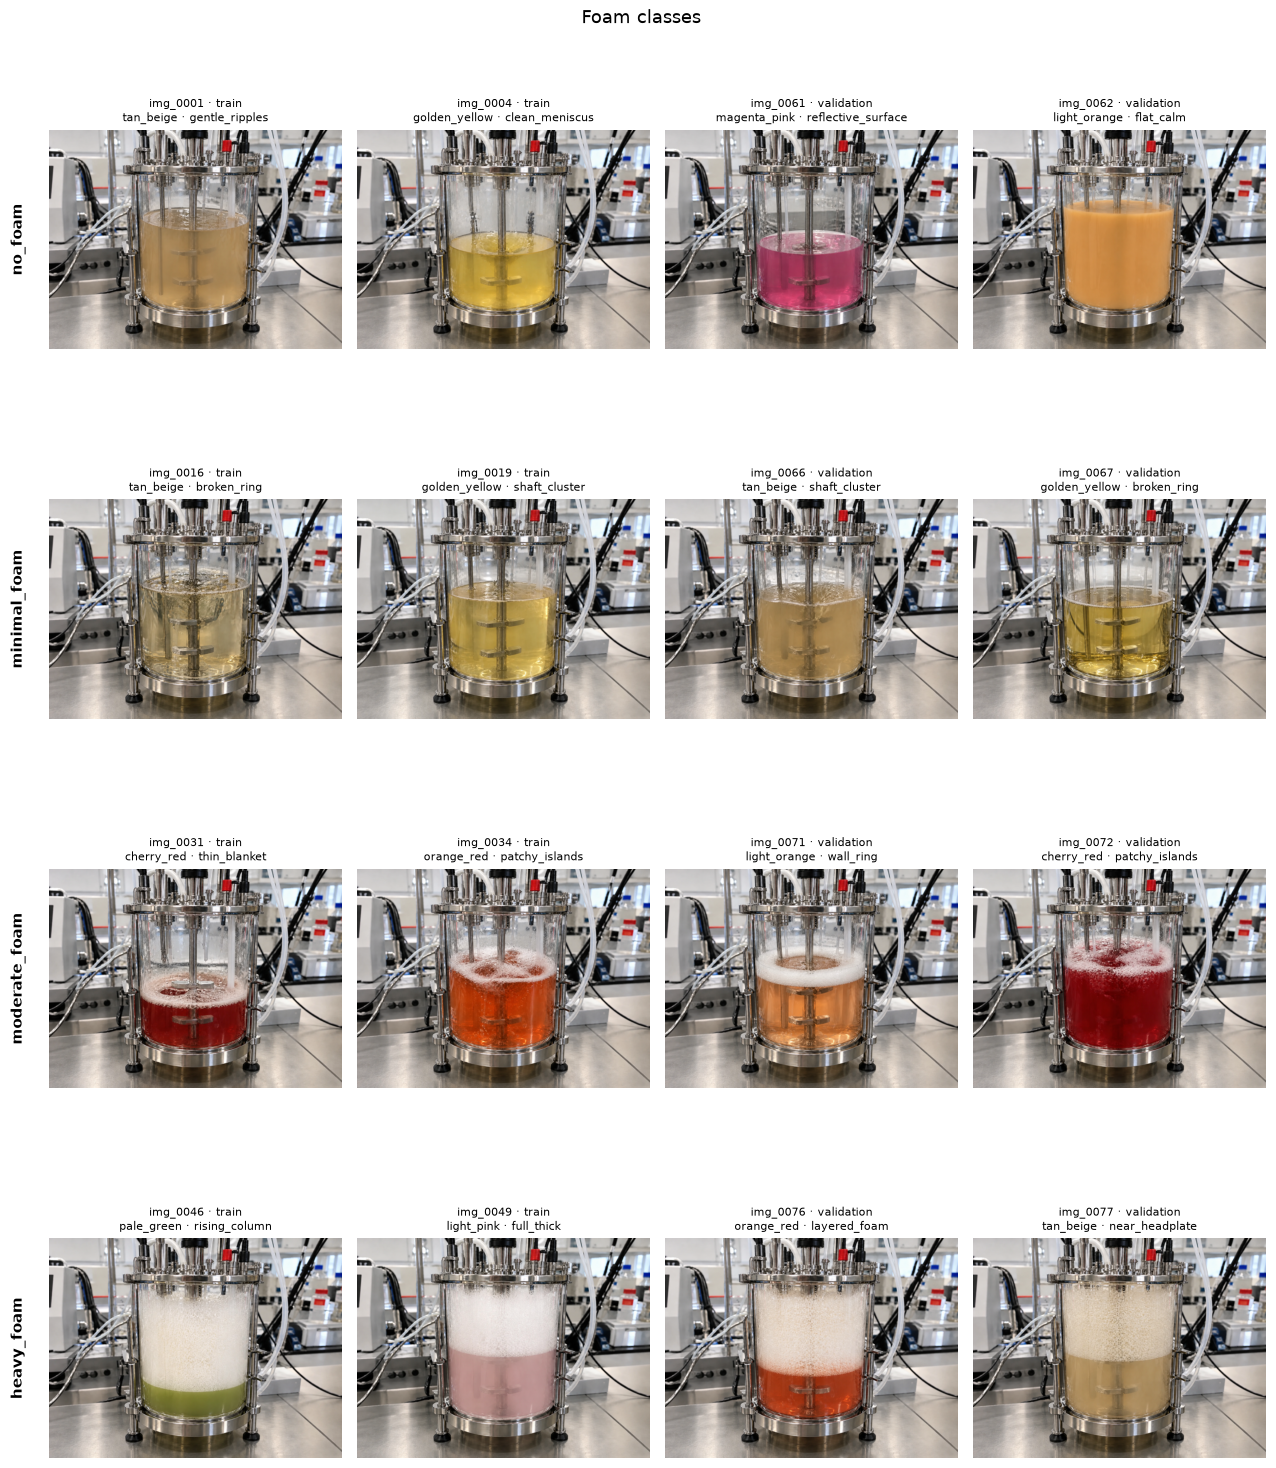

In [17]:
show_class_gallery(images)

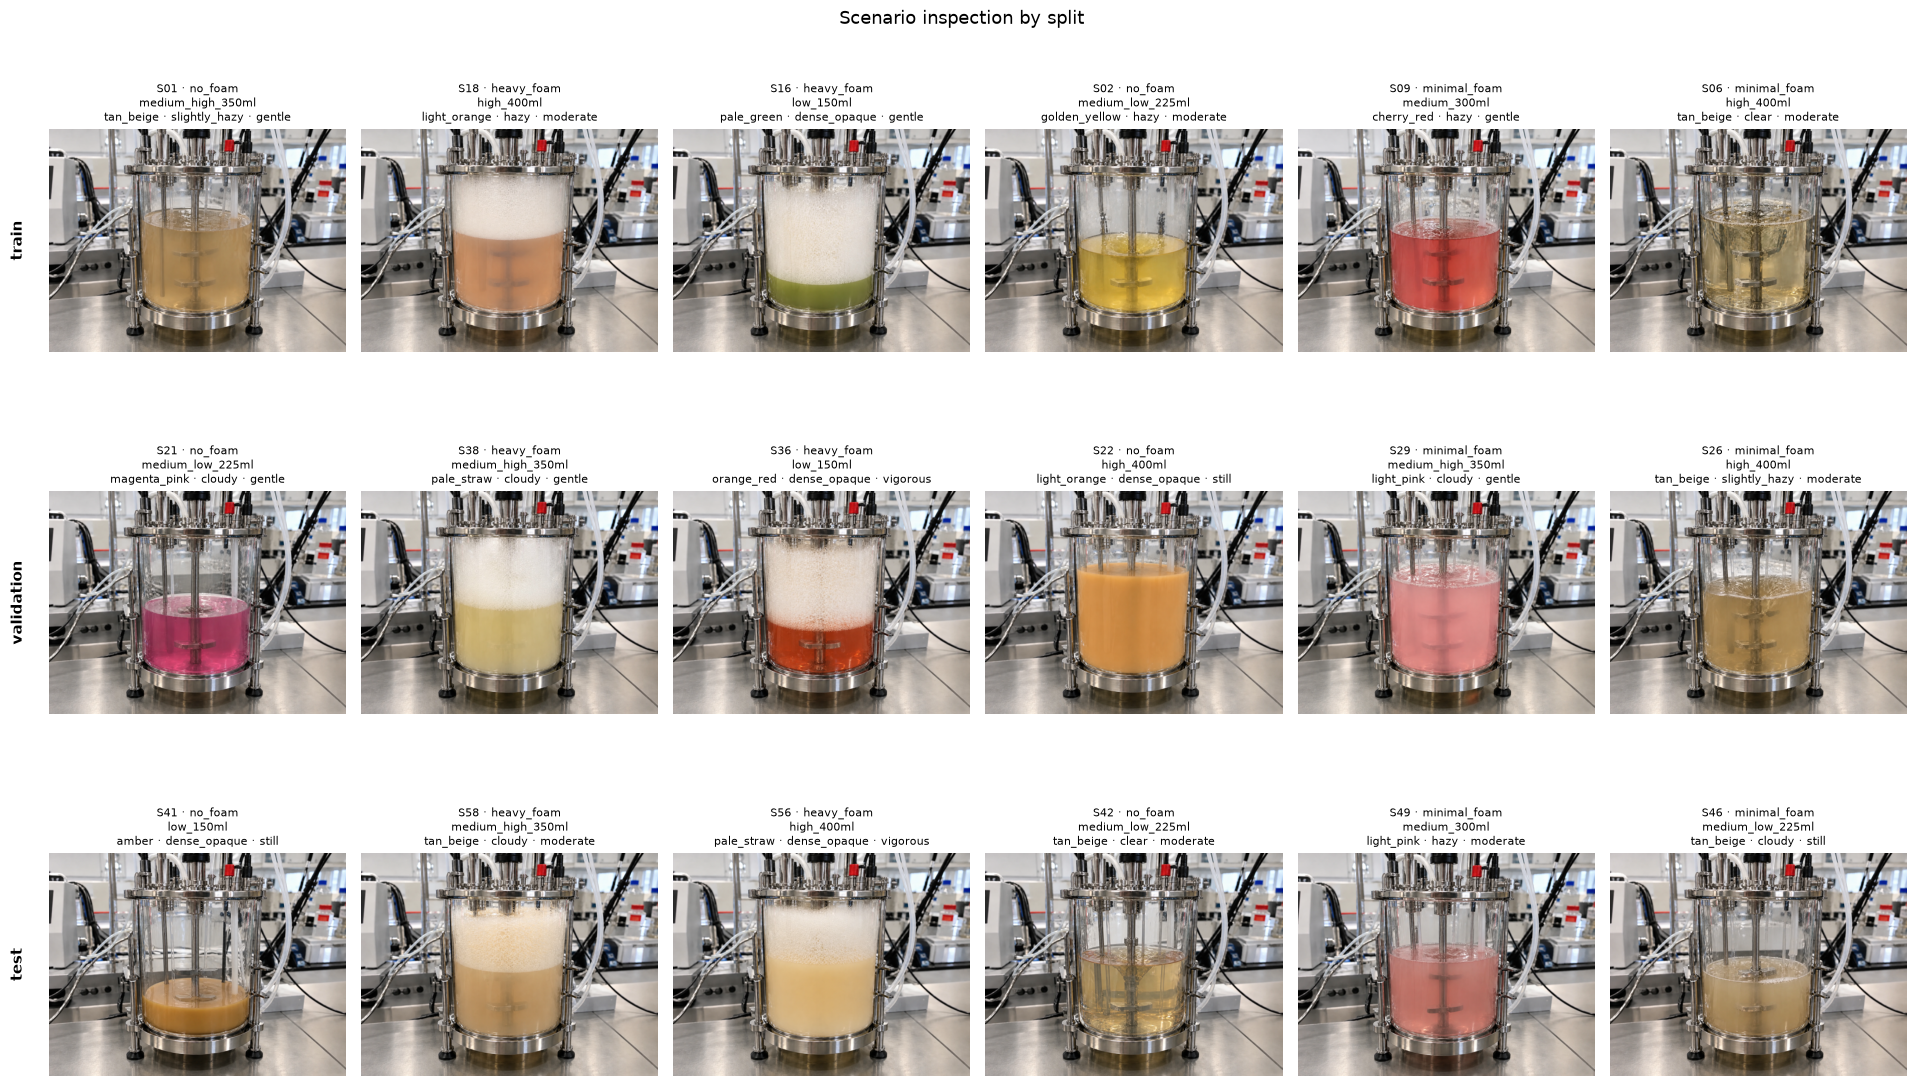

In [18]:
show_scenario_examples(images)

### Validation results

Warnings and failures from Section 9 (also saved in `metadata/validation_report.csv`). During a dry run or a
test run, the count checks fail simply because the dataset is not complete yet.

In [19]:
show_validation_warnings(validation_report)
if not similarity_pairs.empty:
    print("Closest cross-split pairs (smallest dHash distance first) — inspect these visually:")
    display(similarity_pairs[similarity_pairs["cross_split"]].head(10))

⚠️  0 FAIL / 1815 WARN:


,check,status,details
0,cross_split_similarity,WARN,img_0011 (train) ~ img_0073 (validation): distance 0.008 — review manually
1,cross_split_similarity,WARN,img_0073 (validation) ~ img_0099 (test): distance 0.012 — review manually
2,cross_split_similarity,WARN,img_0053 (train) ~ img_0080 (validation): distance 0.012 — review manually
3,cross_split_similarity,WARN,img_0044 (train) ~ img_0092 (test): distance 0.012 — review manually
4,cross_split_similarity,WARN,img_0003 (train) ~ img_0066 (validation): distance 0.012 — review manually
...,...,...,...
1810,cross_split_similarity,WARN,img_0035 (train) ~ img_0081 (test): distance 0.078 — review manually
1811,cross_split_similarity,WARN,img_0034 (train) ~ img_0079 (validation): distance 0.078 — review manually
1812,cross_split_similarity,WARN,img_0012 (train) ~ img_0097 (test): distance 0.078 — review manually
1813,cross_split_similarity,WARN,img_0007 (train) ~ img_0064 (validation): distance 0.078 — review manually


,check,status,details
0,similarity_calibration,INFO,"within-scenario distance: min 0.016, median 0.045"
1,similarity_calibration,INFO,closest cross-split pair distance: 0.008


Closest cross-split pairs (smallest dHash distance first) — inspect these visually:


,image_a,image_b,split_a,split_b,scenario_a,scenario_b,distance,cross_split,same_scenario
1,img_0011,img_0073,train,validation,S04,S33,0.0078,True,False
2,img_0073,img_0099,validation,test,S33,S59,0.0117,True,False
3,img_0053,img_0080,train,validation,S18,S40,0.0117,True,False
4,img_0044,img_0092,train,test,S15,S52,0.0117,True,False
5,img_0003,img_0066,train,validation,S01,S26,0.0117,True,False
7,img_0002,img_0075,train,validation,S01,S35,0.0117,True,False
9,img_0020,img_0075,train,validation,S07,S35,0.0156,True,False
10,img_0017,img_0066,train,validation,S06,S26,0.0156,True,False
11,img_0012,img_0075,train,validation,S04,S35,0.0156,True,False
12,img_0070,img_0081,validation,test,S30,S41,0.0156,True,False


---
## Phase 1 complete

When validation shows **100/100 images** and no FAIL rows, the dataset in `data/` and the metadata in
`metadata/` are ready for **Phase 2 (model training)**. Do not move files between split folders — the splits
were fixed before generation to prevent scenario leakage.